In [1]:
import json
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

from src.vlm.color_signal import (
    build_color_signal_text,
    build_swatch_intro_text,
    build_swatch_palette,
    compute_whole_crop_color_index,
    nearest_swatch_label,
    render_swatch_strip_image,
    sample_multi_point_colors,
)
from src.vlm.cropping import load_crop
from src.vlm.prompting import build_messages

ADJUSTMENT_CFG = {"type": "brightness_contrast", "brightness": 1.2, "contrast": 0.8}
print("project_root:", PROJECT_ROOT)

project_root: /home/jovyan/aicon-gamma-datavol-1/hjgoh/detect-and-reason


## 샘플 crop 2장 로드

- `record_a`: 일반적인 crop
- `record_b`: `stereo20190405_133623_p2_snap_082.jpg`의 crop — 260908 overlay/color-signal 실험 모두에서 semi-ripe가 fully-ripe로 오분류된 케이스

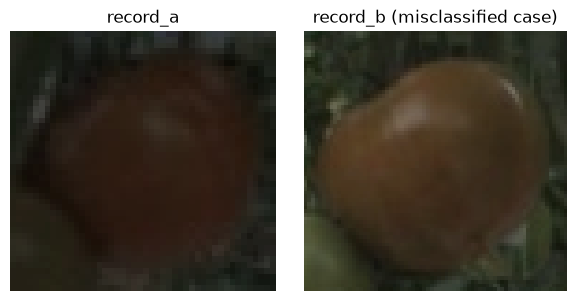

In [2]:
cache_path = (
    PROJECT_ROOT
    / "result/detection_reasoning/tomatod/rf_detr_1cls_prediction/vlm_cache"
    / "test_normalized_input_detections.json"
)
records = json.loads(cache_path.read_text())["records"]

record_a = next(r for r in records if r["record_id"] == "stereo20190406_054921_p0_snap_122#0")
record_b = next(r for r in records if r["record_id"] == "stereo20190405_133623_p2_snap_082#1")

crop_a = load_crop(record_a, expand_ratio=0.1, min_size=32, adjustment_cfg=ADJUSTMENT_CFG)
crop_b = load_crop(record_b, expand_ratio=0.1, min_size=32, adjustment_cfg=ADJUSTMENT_CFG)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(crop_a); axes[0].set_title("record_a"); axes[0].axis("off")
axes[1].imshow(crop_b); axes[1].set_title("record_b (misclassified case)"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## 1) whole_crop_index — crop 전체 평균 CIELAB

In [3]:
whole_a = compute_whole_crop_color_index(crop_a, adjustment_cfg=ADJUSTMENT_CFG)
whole_b = compute_whole_crop_color_index(crop_b, adjustment_cfg=ADJUSTMENT_CFG)
print("record_a whole_crop_index:", whole_a)
print("record_b whole_crop_index:", whole_b)

print()
print("[record_a 프롬프트에 삽입되는 텍스트]")
print(build_color_signal_text("whole_crop_index", whole_a))
print()
print("[record_b 프롬프트에 삽입되는 텍스트]")
print(build_color_signal_text("whole_crop_index", whole_b))

record_a whole_crop_index: {'l': 14.94, 'a': 1.98, 'b': 6.91, 'hue_deg': 74.0, 'chroma': 7.19}
record_b whole_crop_index: {'l': 25.41, 'a': -0.08, 'b': 11.21, 'hue_deg': 90.4, 'chroma': 11.21}

[record_a 프롬프트에 삽입되는 텍스트]
Measured crop color (CIELAB, whole-crop average): hue=74.0°, chroma=7.19, a*=1.98, b*=6.91. Lower hue (roughly 0-60°) indicates more red, higher hue (roughly 100-140°) indicates more green. Use this as a supporting numeric cue alongside the visual appearance.

[record_b 프롬프트에 삽입되는 텍스트]
Measured crop color (CIELAB, whole-crop average): hue=90.4°, chroma=11.21, a*=-0.08, b*=11.21. Lower hue (roughly 0-60°) indicates more red, higher hue (roughly 100-140°) indicates more green. Use this as a supporting numeric cue alongside the visual appearance.


## 2) multi_point_sample — crop 내부 7개 지점 스포이딩

각 점은 `patch_radius=2`짜리 작은 이웃 평균으로 뜬다. 점 위치를 crop 위에 표시해서
실제로 어디를 스포이딩했는지 확인한다.

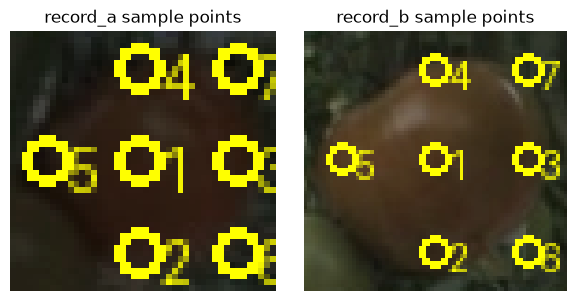

record_a multi_point_sample:
{
  "points": [
    {
      "x": 22,
      "y": 22,
      "l": 15.46,
      "a": 6.47,
      "b": 10.21,
      "hue_deg": 57.6,
      "chroma": 12.08
    },
    {
      "x": 22,
      "y": 38,
      "l": 15.88,
      "a": 4.83,
      "b": 7.54,
      "hue_deg": 57.4,
      "chroma": 8.96
    },
    {
      "x": 39,
      "y": 22,
      "l": 14.99,
      "a": 5.69,
      "b": 9.99,
      "hue_deg": 60.3,
      "chroma": 11.5
    },
    {
      "x": 22,
      "y": 6,
      "l": 12.73,
      "a": 1.88,
      "b": 6.43,
      "hue_deg": 73.8,
      "chroma": 6.7
    },
    {
      "x": 6,
      "y": 22,
      "l": 10.13,
      "a": 2.6,
      "b": 5.35,
      "hue_deg": 64.1,
      "chroma": 5.95
    },
    {
      "x": 39,
      "y": 38,
      "l": 15.81,
      "a": -1.08,
      "b": 4.36,
      "hue_deg": 103.9,
      "chroma": 4.49
    },
    {
      "x": 39,
      "y": 6,
      "l": 11.18,
      "a": -0.83,
      "b": 5.08,
      "hue_deg": 99.3,
      "chr

In [4]:
def draw_sample_points(crop: Image.Image, sampled: dict) -> Image.Image:
    vis = crop.copy()
    draw = ImageDraw.Draw(vis)
    for i, point in enumerate(sampled["points"], start=1):
        x, y = point["x"], point["y"]
        radius = 4
        draw.ellipse([x - radius, y - radius, x + radius, y + radius], outline=(255, 255, 0), width=2)
        draw.text((x + radius, y - radius), str(i), fill=(255, 255, 0))
    return vis

multi_a = sample_multi_point_colors(crop_a, num_points=7, exclude_border_ratio=0.15, patch_radius=2, adjustment_cfg=ADJUSTMENT_CFG)
multi_b = sample_multi_point_colors(crop_b, num_points=7, exclude_border_ratio=0.15, patch_radius=2, adjustment_cfg=ADJUSTMENT_CFG)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(draw_sample_points(crop_a, multi_a)); axes[0].set_title("record_a sample points"); axes[0].axis("off")
axes[1].imshow(draw_sample_points(crop_b, multi_b)); axes[1].set_title("record_b sample points"); axes[1].axis("off")
plt.tight_layout()
plt.show()

print("record_a multi_point_sample:")
print(json.dumps(multi_a, indent=2))
print()
print("record_b multi_point_sample:")
print(json.dumps(multi_b, indent=2))

In [5]:
print("[record_a 프롬프트에 삽입되는 텍스트]")
print(build_color_signal_text("multi_point_sample", multi_a))
print()
print("[record_b 프롬프트에 삽입되는 텍스트]")
print(build_color_signal_text("multi_point_sample", multi_b))

[record_a 프롬프트에 삽입되는 텍스트]
Measured crop color from 7 sampled surface points (median CIELAB): hue=68.0°, chroma=6.94, a*=2.6, b*=6.43. Surface color variation across sampled points: blotchy (high color variation across the surface) (hue std=18.5°). Lower hue indicates more red, higher hue indicates more green. Use this as a supporting numeric cue alongside the visual appearance.

[record_b 프롬프트에 삽입되는 텍스트]
Measured crop color from 7 sampled surface points (median CIELAB): hue=76.1°, chroma=12.51, a*=3.0, b*=12.15. Surface color variation across sampled points: blotchy (high color variation across the surface) (hue std=23.9°). Lower hue indicates more red, higher hue indicates more green. Use this as a supporting numeric cue alongside the visual appearance.


## 3) swatch_match — 참조 색상 스와치 이미지

익음 hue 궤적(20°~130°)을 따라 6개 swatch(A~F)를 만들고, crop의 whole-crop hue와
가장 가까운 swatch를 (분석용으로만) 계산한다. 모델에게는 이 swatch 이미지 자체만
보여주고, 어떤 swatch를 골랐는지 강제로 출력시키지는 않는다.

swatches: [{'label': 'A', 'hue_deg': 20.0, 'rgb': (218, 89, 102)}, {'label': 'B', 'hue_deg': 42.0, 'rgb': (208, 99, 70)}, {'label': 'C', 'hue_deg': 64.0, 'rgb': (189, 114, 43)}, {'label': 'D', 'hue_deg': 86.0, 'rgb': (162, 127, 26)}, {'label': 'E', 'hue_deg': 108.0, 'rgb': (129, 138, 30)}, {'label': 'F', 'hue_deg': 130.0, 'rgb': (90, 146, 53)}]

swatch intro text: Reference color swatches (A, B, C, D, E, F, left to right) spanning typical tomato ripening colors. Compare the target crop's color to these swatches only as a coarse anchor for where it falls on the color spectrum — make your final judgment mainly from the crop image itself.


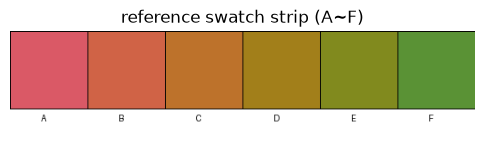

record_a nearest_swatch_label: C
record_b nearest_swatch_label: D


In [6]:
swatches = build_swatch_palette(count=6, hue_range_deg=(20.0, 130.0), lightness=55.0, chroma=55.0)
swatch_strip = render_swatch_strip_image(swatches)

print("swatches:", swatches)
print()
print("swatch intro text:", build_swatch_intro_text(swatches))

plt.figure(figsize=(6, 2))
plt.imshow(swatch_strip)
plt.axis("off")
plt.title("reference swatch strip (A~F)")
plt.show()

print("record_a nearest_swatch_label:", nearest_swatch_label(whole_a["hue_deg"], swatches))
print("record_b nearest_swatch_label:", nearest_swatch_label(whole_b["hue_deg"], swatches))

## 4) build_messages에 실제로 어떻게 들어가는지

세 모드 각각 `build_messages`를 호출했을 때 user turn에 어떤 순서로 텍스트/이미지 블록이 쌓이는지 구조만 뽑아서 확인한다 (실제 image 객체는 크기만 표시).

In [7]:
def summarize_messages(messages):
    for message in messages:
        role = message["role"]
        print(f"--- role={role} ---")
        for block in message["content"]:
            if block["type"] == "text":
                preview = block["text"][:120].replace("\n", " ")
                print(f"  [text] {preview}...")
            elif block["type"] == "image":
                print(f"  [image] size={block['image'].size}")

prompt_cfg = {
    "use_reasoning": True,
    "use_examples": False,
    "use_color_guide": True,
    "include_bbox_json": True,
    "reasoning_max_words": 35,
    "class_map": {0: "fully-ripe", 1: "semi-ripe", 2: "unripe"},
}

print("=== whole_crop_index ===")
messages = build_messages(
    record=record_b,
    crop_image=crop_b,
    prompt_cfg=prompt_cfg,
    color_signal_text=build_color_signal_text("whole_crop_index", whole_b),
)
summarize_messages(messages)

print()
print("=== multi_point_sample ===")
messages = build_messages(
    record=record_b,
    crop_image=crop_b,
    prompt_cfg=prompt_cfg,
    color_signal_text=build_color_signal_text("multi_point_sample", multi_b),
)
summarize_messages(messages)

print()
print("=== swatch_match ===")
messages = build_messages(
    record=record_b,
    crop_image=crop_b,
    prompt_cfg=prompt_cfg,
    color_signal_image=swatch_strip,
    color_signal_intro_text=build_swatch_intro_text(swatches),
)
summarize_messages(messages)

=== whole_crop_index ===
--- role=system ---
  [text] You classify tomato ripeness from a detector crop. Always return strict JSON only. Do not add markdown or extra text....
--- role=user ---
  [text] Target crop image to classify:...
  [image] size=(71, 70)
  [text] Measured crop color (CIELAB, whole-crop average): hue=90.4°, chroma=11.21, a*=-0.08, b*=11.21. Lower hue (roughly 0-60°)...
  [text] Classify only the tomato shown in the crop image. Use the crop appearance as primary evidence.  Class definitions: - ful...

=== multi_point_sample ===
--- role=system ---
  [text] You classify tomato ripeness from a detector crop. Always return strict JSON only. Do not add markdown or extra text....
--- role=user ---
  [text] Target crop image to classify:...
  [image] size=(71, 70)
  [text] Measured crop color from 7 sampled surface points (median CIELAB): hue=76.1°, chroma=12.51, a*=3.0, b*=12.15. Surface co...
  [text] Classify only the tomato shown in the crop image. Use the crop appear

## 5) swatch를 crop에 직접 붙이는 방식 — 3가지 ablation

260909에 추가한 방식: swatch를 별도 이미지 블록으로 주지 않고, **crop 오른쪽에 세로로 붙여서
하나의 이미지**로 합친 뒤 그 합성 이미지 자체를 crop_image로 사용한다
(`compose_crop_with_vertical_swatch`). 좌표/수치 텍스트는 전혀 넣지 않고 이미지만 준다.

3가지 config로 실험한다 (`config/vlm/qwen3_vl_4b_zs_3cls_tomatod_bc_swatch_{only,with_example,with_reasoning}.yaml`):
1. **swatch_only**: exemplar 없이 swatch만
2. **swatch_with_example**: exemplar 추가
3. **swatch_with_reasoning**: exemplar + Step1을 명시적으로 "swatch와 비교"로 변경 (`swatch_reasoning_hint: true`)

swatches (5단계): [{'label': 'A', 'hue_deg': 20.0, 'rgb': (218, 89, 102)}, {'label': 'B', 'hue_deg': 47.5, 'rgb': (204, 103, 63)}, {'label': 'C', 'hue_deg': 75.0, 'rgb': (176, 121, 33)}, {'label': 'D', 'hue_deg': 102.5, 'rgb': (138, 136, 27)}, {'label': 'E', 'hue_deg': 130.0, 'rgb': (90, 146, 53)}]

attached swatch note (crop 이미지 앞에 붙는 안내 문구):
Reference color swatches (A, B, C, D, E, top to bottom) are attached to the right side of this image, spanning typical tomato ripening colors. Compare the tomato's color to these swatches only as a coarse anchor for where it falls on the color spectrum — make your final judgment mainly from the tomato crop itself.


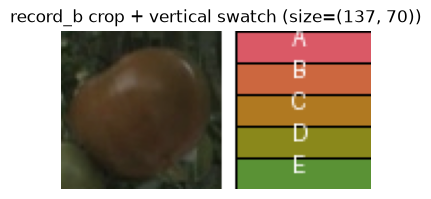

In [8]:
from src.vlm.color_signal import build_attached_swatch_note, compose_crop_with_vertical_swatch
from src.vlm.config import load_vlm_config
from src.vlm.prompting import build_instruction_text

swatches5 = build_swatch_palette(count=5, hue_range_deg=(20.0, 130.0), lightness=55.0, chroma=55.0)
combined_b = compose_crop_with_vertical_swatch(crop_b, swatches5, swatch_width=60, gap=6)

print("swatches (5단계):", swatches5)
print()
print("attached swatch note (crop 이미지 앞에 붙는 안내 문구):")
print(build_attached_swatch_note(swatches5))

plt.figure(figsize=(4, 3))
plt.imshow(combined_b)
plt.title(f"record_b crop + vertical swatch (size={combined_b.size})")
plt.axis("off")
plt.show()

### swatch_reasoning_hint가 instruction 텍스트를 어떻게 바꾸는지

In [9]:
class_map = {0: "fully-ripe", 1: "semi-ripe", 2: "unripe"}
base_prompt_cfg = {"use_reasoning": True, "use_color_guide": True, "include_bbox_json": True, "reasoning_max_words": 35}

print("=== swatch_reasoning_hint: false (기본 Step1) ===")
print(build_instruction_text(
    record=record_b,
    prompt_cfg={**base_prompt_cfg, "color_signal": {"swatch_reasoning_hint": False}},
    class_map=class_map,
))

print("=== swatch_reasoning_hint: true (Step1이 swatch 비교로 바뀜) ===")
print(build_instruction_text(
    record=record_b,
    prompt_cfg={**base_prompt_cfg, "color_signal": {"swatch_reasoning_hint": True}},
    class_map=class_map,
))

=== swatch_reasoning_hint: false (기본 Step1) ===
Classify only the tomato shown in the crop image.
Use the crop appearance as primary evidence.

Class definitions:
- fully-ripe: red is dominant overall, even with small shadow, highlight, or dark red regions
- semi-ripe: clear green/yellow/orange transition remains over a meaningful area
- unripe: green surface remains dominant
- If red is dominant and no clear green area remains, choose fully-ripe.

Input bbox JSON (copy these values exactly into output.bbox): {"x1": 243.63, "y1": 193.0, "x2": 303.42, "y2": 251.1}

Reasoning instruction:
Step1: Describe visible color pattern and surface cues.
Step2: Decide ripeness class from the visual evidence.

Return JSON that follows this schema exactly:
{
  "class_name": one of ["fully-ripe", "semi-ripe", "unripe"],
  "bbox": {"x1": number, "y1": number, "x2": number, "y2": number},
  "reasoning": string
}
Rules:
- output valid JSON only
- do not add extra keys
- bbox must exactly copy the input b

### 실제 config 3개를 그대로 로드해서 build_messages 구조 확인

실제 파이프라인이 쓰는 config 파일을 그대로 불러와서, 각 모드에서 crop_image 자체가 어떻게
바뀌고(swatch가 붙은 합성 이미지가 되는지) instruction이 어떻게 달라지는지 확인한다.

In [10]:
PROJECT_ROOT_PATH = PROJECT_ROOT

for config_name in [
    "qwen3_vl_4b_zs_3cls_tomatod_bc_swatch_only",
    "qwen3_vl_4b_zs_3cls_tomatod_bc_swatch_with_example",
    "qwen3_vl_4b_zs_3cls_tomatod_bc_swatch_with_reasoning",
]:
    vlm_cfg, _ = load_vlm_config(config_name, project_root=PROJECT_ROOT_PATH)
    swatch_cfg = vlm_cfg["prompt"]["color_signal"]["swatch"]
    palette = build_swatch_palette(
        count=swatch_cfg["count"],
        hue_range_deg=tuple(swatch_cfg["hue_range_deg"]),
        lightness=swatch_cfg["lightness"],
        chroma=swatch_cfg["chroma"],
    )
    combined = compose_crop_with_vertical_swatch(
        crop_b, palette, swatch_width=swatch_cfg["swatch_width"], gap=swatch_cfg["gap"]
    )
    prompt_cfg = dict(vlm_cfg["prompt"])
    prompt_cfg["class_map"] = vlm_cfg["task"]["class_map"]
    if prompt_cfg.get("use_examples"):
        # 데모 목적: example_picker 없이 exemplar 유무 표시만 확인 (실제 pick은 classification.py에서 수행)
        prompt_cfg["use_examples"] = False
    messages = build_messages(
        record=record_b,
        crop_image=combined,
        prompt_cfg=prompt_cfg,
        crop_intro_note=build_attached_swatch_note(palette),
    )
    print(f"=== {config_name} ===")
    print(f"use_examples(config)={vlm_cfg['prompt']['use_examples']} swatch_reasoning_hint={vlm_cfg['prompt']['color_signal']['swatch_reasoning_hint']} attach_to_crop={swatch_cfg['attach_to_crop']}")
    summarize_messages(messages)
    print()

=== qwen3_vl_4b_zs_3cls_tomatod_bc_swatch_only ===
use_examples(config)=False swatch_reasoning_hint=False attach_to_crop=True
--- role=system ---
  [text] You classify tomato ripeness from a detector crop. Always return strict JSON only. Do not add markdown or extra text....
--- role=user ---
  [text] Target crop image to classify:...
  [text] Reference color swatches (A, B, C, D, E, top to bottom) are attached to the right side of this image, spanning typical t...
  [image] size=(137, 70)
  [text] Classify only the tomato shown in the crop image. Use the crop appearance as primary evidence.  Class definitions: - ful...

=== qwen3_vl_4b_zs_3cls_tomatod_bc_swatch_with_example ===
use_examples(config)=True swatch_reasoning_hint=False attach_to_crop=True
--- role=system ---
  [text] You classify tomato ripeness from a detector crop. Always return strict JSON only. Do not add markdown or extra text....
--- role=user ---
  [text] Target crop image to classify:...
  [text] Reference color sw